# Navi-Gator — Classifying Road Condition from Overhead Imagery
### A working rough draft  ·  Vyrareth  ·  Sprint 2

> **What this notebook is (and isn't).**
> This is an early, exploratory pass at the hardest open question in our project:
> *how do we decide, from a satellite/aerial picture, whether a road is a Level 5
> (great) or a Level 1 (do-not-travel)?* It is **not** the finished classifier.
> It's me (a) pinning down a defensible rating scheme, (b) proving the visual signal
> is actually measurable, and (c) being honest about the roadblocks I'm still working
> through. The code runs end-to-end on illustrative chips so the method is visible;
> swapping in real NJGIN chips is the next step.

## 1. The problem, and the one constraint that shapes everything

Our data source is **NJGIN orthoimagery** — shot *straight down*. So the classifier can
only ever learn from what's visible from above. That single fact decides the whole design:

| We CAN see from overhead ✅ | We CANNOT reliably see ❌ |
|---|---|
| Cracking (alligator / block / longitudinal) — as texture & edges | Rutting depth |
| Patches & repairs (brightness mismatch) | Ride roughness / IRI |
| Potholes & dark depressions (dark blobs) | Hairline cracks below ~1 px |
| Oxidation / aging (fresh = dark, old = grey) | Subsurface / base failure |
| Raveling / surface break-up (texture) | Skid resistance |
| Faded markings, crumbling edges, standing water | |

**So the honest scope is:** we grade *coarse, visible surface distress* — **not** ride quality.
That's a limitation I state up front rather than pretend around.

## 2. Don't invent a scale — anchor to a real one

Pavement rating is a standardized field, so our 1–5 isn't arbitrary. It's **PASER**
(Pavement Surface Evaluation and Rating — the DOT *visual surface* scale, normally 1–10)
compressed to 5 and restricted to what's visible from above. (PCI 0–100 and FHWA HPMS
cracking % are the other standards; HPMS is already one of our data sources.)

| Navi-Gator | PASER | PCI |
|:--:|:--:|:--:|
| 5 Excellent | 9–10 | 85–100 |
| 4 Good | 7–8 | 70–85 |
| 3 Fair | 5–6 | 55–70 |
| 2 Poor | 3–4 | 40–55 |
| 1 Do-Not-Travel | 1–2 | 0–40 |

## 3. The rubric — what each level *looks like from above*

- **5 Excellent** — uniform dark asphalt, no cracks, crisp markings → *route freely*
- **4 Good** — slightly grey, a few isolated cracks / one patch → *no penalty*
- **3 Fair** — aged grey, scattered cracks or several patches → *small routing penalty*
- **2 Poor** — connected/alligator cracking, potholes, ragged edges → *avoid if alternative*
- **1 Do-Not-Travel** — surface shattered, many potholes, crumbling edges → *exclude from routing*

The idea below is to turn each of those word-pictures into **numbers** so the rating is
repeatable and, later, learnable by a CNN.

## 4. Setup

Standard scientific-Python stack (same `scikit-image` Don is already using on the
preprocessing side, so the team shares one toolchain).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import img_as_float, img_as_ubyte, color
from skimage.feature import canny
from skimage.filters.rank import entropy
from skimage.morphology import disk, remove_small_objects
from skimage.measure import label
%matplotlib inline
print("environment ready")

environment ready


## 5. Illustrative chips (synthetic stand-ins)

I don't have a labeled NJGIN set yet, so to demonstrate the method end-to-end I generate
three **synthetic** road chips — a clean one, an aged/patched one, and a cracked+potholed
one. These are stand-ins purely to show the pipeline works; the real input will be cropped
NJGIN chips (from Cris's auto-screenshot tool or the NJGIN export service).

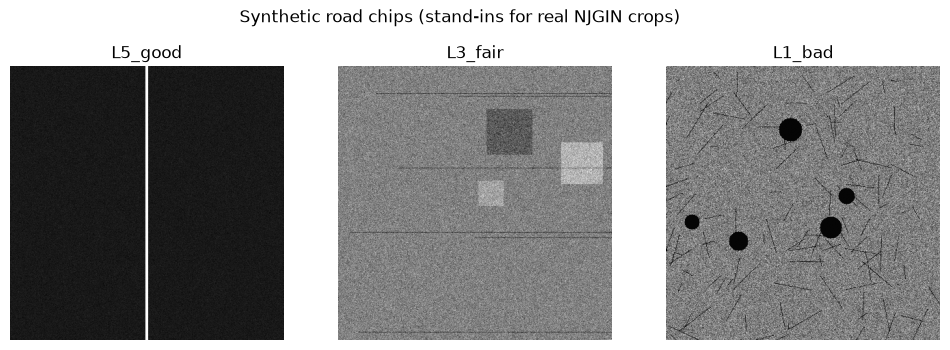

In [2]:
rng = np.random.default_rng(7)
H = W = 400

def base(level_dark):
    return np.clip(level_dark + rng.normal(0, 0.015, (H, W)), 0, 1)

# Level 5: fresh dark asphalt, smooth, crisp lane line
g5 = base(0.22); g5[:, 198:202] = 0.85

# Level 3: aged grey, a few patches + thin cracks (blotchy)
g3 = base(0.40) + rng.normal(0, 0.05, (H, W))
for _ in range(3):
    y, x, s = rng.integers(40,340), rng.integers(40,340), rng.integers(30,70)
    g3[y:y+s, x:x+s] += rng.uniform(-0.18, 0.18)
for _ in range(6):
    y = rng.integers(0,H); g3[y:y+1, rng.integers(0,200):] -= 0.15
g3 = np.clip(g3, 0, 1)

# Level 1: heavy alligator cracking + potholes
g1 = base(0.5) + rng.normal(0, 0.12, (H, W))
for _ in range(120):
    y, x = rng.integers(0,H), rng.integers(0,W)
    l = rng.integers(10,60); ang = rng.uniform(0, np.pi)
    for t in range(l):
        yy, xx = int(y+t*np.sin(ang)), int(x+t*np.cos(ang))
        if 0 <= yy < H and 0 <= xx < W: g1[yy,xx] -= 0.35
for _ in range(5):
    y, x, r = rng.integers(30,370), rng.integers(30,370), rng.integers(8,18)
    yy, xx = np.ogrid[:H,:W]; g1[(yy-y)**2+(xx-x)**2 <= r*r] = 0.02
g1 = np.clip(g1, 0, 1)

chips = {"L5_good": g5, "L3_fair": g3, "L1_bad": g1}

fig, ax = plt.subplots(1, 3, figsize=(12,4))
for a,(name,g) in zip(ax, chips.items()):
    a.imshow(g, cmap="gray"); a.set_title(name); a.axis("off")
plt.suptitle("Synthetic road chips (stand-ins for real NJGIN crops)"); plt.show()

## 6. Turning visible distress into numbers

Five interpretable features, each tied to a distress type we can actually see from above.
`mean_brightness` is **reported, not scored** — concrete vs. asphalt differ in albedo, so it
would confound the score; it's useful context, not a judge.

In [3]:
def features(g):
    edges = canny(g, sigma=1.5)                       # cracking
    ent   = entropy(img_as_ubyte(g), disk(5))         # raveling / break-up
    thr   = np.percentile(g, 8)
    dark  = remove_small_objects(g < thr, min_size=max(16, int(0.0008*g.size)))  # potholes
    return {
        "edge_density":    float(edges.mean()),
        "texture_entropy": float(ent.mean()),
        "dark_spot_frac":  float(dark.mean()),
        "n_dark_spots":    int(label(dark).max()),
        "blotchiness":     float(g.std()),            # patching / uneven aging
        "mean_brightness": float(g.mean()),           # oxidation (reported only)
    }, edges, ent, dark

# Calibration constants -- TUNE THESE on real NJGIN chips. Ranking is robust even if absolute cutoffs aren't.
SCALE  = {"edges":0.14, "entropy":4.2, "dark":0.06, "blotch":0.22}
WEIGHT = {"edges":0.40, "entropy":0.25, "dark":0.20, "blotch":0.15}
NAME   = {5:"Excellent",4:"Good",3:"Fair",2:"Poor",1:"Do-Not-Travel"}

def score(f):
    b = (WEIGHT["edges"]*min(f["edge_density"]/SCALE["edges"],1) +
         WEIGHT["entropy"]*min(f["texture_entropy"]/SCALE["entropy"],1) +
         WEIGHT["dark"]*min(f["dark_spot_frac"]/SCALE["dark"],1) +
         WEIGHT["blotch"]*min(f["blotchiness"]/SCALE["blotch"],1))
    return b, int(np.clip(round(5-4*b), 1, 5))

## 7. Run it — do the numbers separate a good road from a bad one?

This is the real test of the idea. If the features can't tell these apart, the whole
approach is wrong. (Watch the `edge_density`, `texture`, and `dark_spot` columns.)

In [4]:
hdr = f"{'chip':<10}{'edges%':>8}{'texture':>9}{'darkspt%':>10}{'blotch':>8}{'bright':>8}{'distress':>10}{'LEVEL':>7}"
print(hdr); print("-"*70)
results = {}
for name, g in chips.items():
    f,_,_,_ = features(g)
    d, lvl = score(f); results[name] = (f,d,lvl)
    print(f"{name:<10}{f['edge_density']*100:>8.2f}{f['texture_entropy']:>9.2f}"
          f"{f['dark_spot_frac']*100:>9.2f}%{f['blotchiness']:>8.3f}{f['mean_brightness']:>8.3f}{d:>10.2f}{lvl:>7}")

print("\nWorst -> best (does this match the eye?):")
for name,(f,d,lvl) in sorted(results.items(), key=lambda kv: -kv[1][1]):
    print(f"  LEVEL {lvl} ({NAME[lvl]:<13}) {name}")

chip        edges%  texture  darkspt%  blotch  bright  distress  LEVEL
----------------------------------------------------------------------
L5_good       0.50     3.76     0.00%   0.064   0.226      0.28      4


/tmp/ipykernel_775/2552935363.py:5: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  dark  = remove_small_objects(g < thr, min_size=max(16, int(0.0008*g.size)))  # potholes


L3_fair       0.50     5.14     1.00%   0.060   0.399      0.34      4


L1_bad       15.02     5.62     1.99%   0.146   0.482      0.82      2

Worst -> best (does this match the eye?):
  LEVEL 2 (Poor         ) L1_bad
  LEVEL 4 (Good         ) L3_fair
  LEVEL 4 (Good         ) L5_good


**Read the result:** the cracked/potholed chip lands far higher on distress (driven by a
large `edge_density` and several detected dark-spots), and the worst→best ordering matches
what the eye says. That's the signal existing and being measurable — the point of this pass.
The absolute Level cutoffs are just the calibration constants, which I'll tune on real NJ chips.

## 8. Seeing *why* — the feature maps

For the clean and the failed chip, visualize the layers the score is built from:
cracking (edges), texture, and detected potholes.

/tmp/ipykernel_775/2552935363.py:5: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  dark  = remove_small_objects(g < thr, min_size=max(16, int(0.0008*g.size)))  # potholes


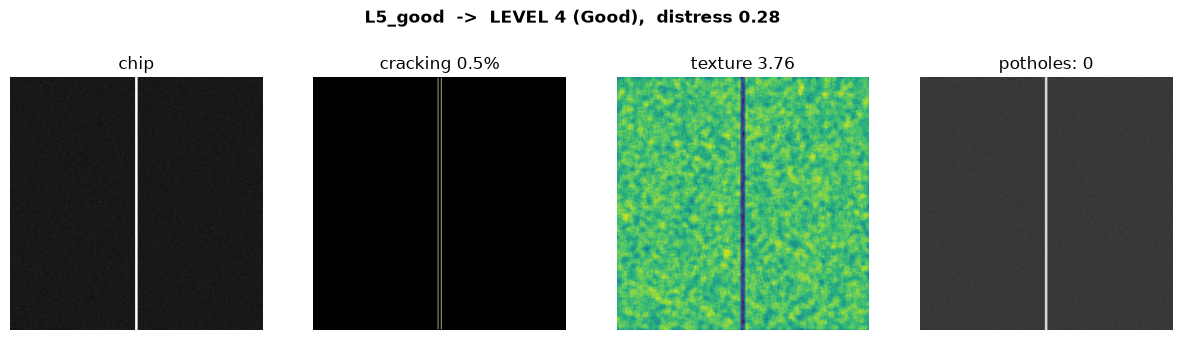

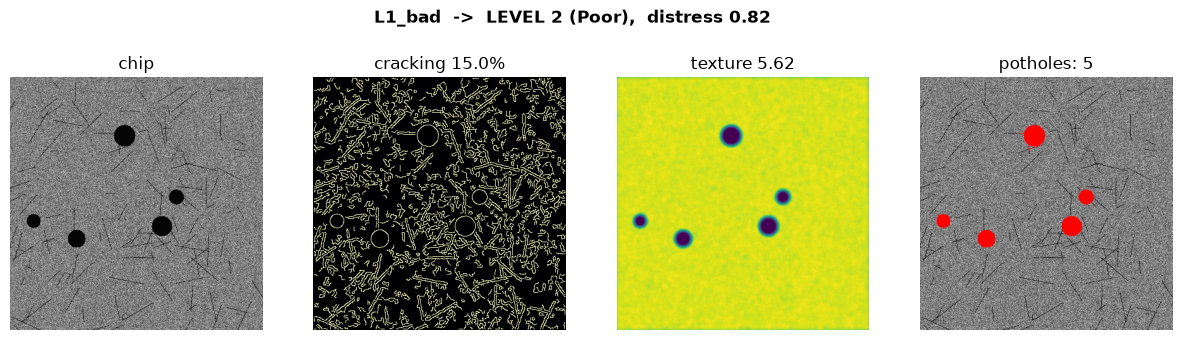

In [5]:
def panel(name):
    g = chips[name]; f, edges, ent, dark = features(g); d, lvl = score(f)
    fig, ax = plt.subplots(1, 4, figsize=(15,4))
    ax[0].imshow(g, cmap="gray"); ax[0].set_title("chip")
    ax[1].imshow(edges, cmap="magma"); ax[1].set_title(f"cracking {f['edge_density']*100:.1f}%")
    ax[2].imshow(ent, cmap="viridis"); ax[2].set_title(f"texture {f['texture_entropy']:.2f}")
    ov = np.dstack([g,g,g]); ov[dark] = [1,0,0]
    ax[3].imshow(ov); ax[3].set_title(f"potholes: {f['n_dark_spots']}")
    for a in ax: a.axis("off")
    plt.suptitle(f"{name}  ->  LEVEL {lvl} ({NAME[lvl]}),  distress {d:.2f}", fontweight="bold"); plt.show()

panel("L5_good")
panel("L1_bad")

## 9. Where I'm stuck — the roadblocks I'm still working through

Being straight about the open problems (this is a rough draft, not a finished system):

1. **Road isolation is the hard wall.** Before any of this runs on a *real* NJGIN tile, we
   have to isolate just the road pixels (strip grass, roofs, cars). Don's first scikit-image
   approach (contrast → morphology → pixel trace) hit accuracy limits on shadow/tree noise and
   broken road continuity. He's pivoting to a published road-extraction method (Li & Briggs,
   2009). Until that's solid, I'm cropping chips to pavement by hand to test the *rating* idea
   in isolation.
2. **No labeled dataset yet.** Everything above runs on synthetic stand-ins. The real next
   step is collecting and hand-labeling actual NJGIN chips (1–5) to both validate the rubric
   and train a CNN.
3. **Resolution ceiling.** At NJGIN GSD we get coarse distress (patches, potholes, alligator
   cracking as texture) but not hairline cracks or rutting — so the scheme is deliberately
   scoped to coarse distress.
4. **Confounds to handle:** shadows, tree cover, cars, wet pavement, and concrete-vs-asphalt
   albedo can all mislead the features. The CNN will need enough varied examples to be robust;
   the heuristic alone won't be.
5. **Calibration.** The Level cutoffs are guesses until tuned on real NJ imagery. The
   worst→best *ranking* is already trustworthy; the absolute thresholds aren't yet.

## 10. The plan from here

1. Pull a handful of real NJGIN chips (via Cris's auto-screenshot tool / NJGIN export) at a
   few known condition levels.
2. Use this heuristic to **pre-rank** a larger pile, then hand-label 1–5 → first training set.
3. Train a CNN on (chip → level); the features here define what it should learn and give a
   baseline to beat.
4. Map the predicted Level to a **routing edge-weight** (5 = ×1.0 … 1 = exclude) so the app
   routes the shortest *good* road, not just the shortest road. **That's the product thesis:
   classify the surface → turn it into a cost → route around the bad roads.**

*Rough draft — feedback welcome on the rating scale and the feature choices before I invest in
labeling a full dataset.*